# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

## Diccionario de Datos

Hay cinco archivos CSV que contienen los datos de los clientes de Megaline, los cuales se utilizarán como tablas de referencia para el análisis de datos. A continuación se describe cada uno de los archivos y sus columnas:

- `megaline_users.csv` (datos sobre los usuarios):
    - `user_id`: identificador único del usuario.
    - `first_name`: nombre del usuario.
    - `last_name`: apellido del usuario.
    - `age`: edad del usuario (en años).
    - `reg_date`: fecha de suscripción (dd, mm, aa).
    - `churn_date`: la fecha en la que el usuario dejó de usar el servicio (si el valor es ausente, la tarifa se estaba usando cuando fue extraída esta base de datos).
    - `city`: ciudad de residencia del usuario.
    - `plan`: nombre de la tarifa.

- `megaline_calls.csv` (datos sobre las llamadas):
    - `id`: identificador único de la llamada.
    - `call_date`: fecha de la llamada.
    - `duration`: duración de la llamada (en minutos).
    - `user_id`: el identificador del usuario que realiza la llamada.

- `megaline_messages.csv` (datos sobre los SMS):
    - `id`: identificador único del SMS.
    - `message_date`: fecha del SMS.
    - `user_id`: el identificador del usuario que manda el SMS.

- `megaline_internet.csv` (datos sobre las sesiones web):
    - `id`: identificador único de la sesión.
    - `mb_used`: el volumen de datos gastados durante la sesión (en megabytes).
    - `session_date`: fecha de la sesión web.
    - `user_id`: identificador del usuario.

- `megaline_plans.csv` (datos sobre las tarifas):
    - `plan_name`: nombre de la tarifa.
    - `usd_monthly_fee`: pago mensual en dólares estadounidenses.
    - `minutes_included`: minutos incluidos al mes.
    - `messages_included`: SMS incluidos al mes.
    - `mb_per_month_included`: datos incluidos al mes (en megabytes).
    - `usd_per_minute`: precio por minuto tras exceder los límites del paquete (por ejemplo, si el paquete incluye 100 minutos, el operador cobrará el minuto 101).
    - `usd_per_message`: precio por SMS tras exceder los límites del paquete.
    - `usd_per_gb`: precio por gigabyte de los datos extra tras exceder los límites del paquete (1 GB = 1024 megabytes).

## Propósito del Proyecto
El propósito de este proyecto es analizar las tarifas prepago Surf y Ultimate de la empresa Megaline, con el objetivo de determinar cuál de ellas genera más ingresos. Para ello, se realizará un análisis preliminar basado en los datos suministrados y de acuerdo con los resultados el equipo de marketing podrá ajustar su presupuesto de publicidad y estrategias de promoción.

## Plan de Acción para el Análisis de Datos
1. **Carga de Datos**: Importar los archivos CSV y cargarlos en dataframes
2. **Exploración Inicial de Datos**: Revisar la estructura de los dataframes, tipos de datos y obtener un resumen de datos.
3. **Limpieza de Datos**: Limpiar los datos identificando y manejando valores nulos, duplicados o inconsistencias en los tipos de datos.
4. **Enriquecimiento de Datos**: Crear nuevas columnas que puedan ser útiles para el análisis, como extracciones de meses, redondeos de cifras y conversiones de unidades.
5. **Cálculo de Métricas Importantes**: Calcular métricas como:
   - Agregación por usuario y por mes
   - Ingresos generados por cada usuario
   - Cálculos de otras métricas como minutos usados, mensajes enviados y datos consumidos.
6. **Análisis Descriptivo y Visualización**: Crear gráficos y tablas para visualizar la distribución de los datos y las diferencias entre las tarifas Surf y Ultimate.
7. **Pruebas de Hipótesis**: Realizar las pruebas de hipótesis necesarias para determinar si las diferencias observadas entre las tarifas son estadísticamente significativas.
8. **Conclusiones y Recomendaciones**: Basado en los hallazgos, proporcionar recomendaciones al equipo de marketing sobre cuál tarifa es más rentable y cómo podrían ajustar sus estrategias de promoción.

## Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np

## 1. Carga de datos

In [2]:
# Carga los archivos de datos en diferentes DataFrames
df_internet = pd.read_csv('data/megaline_internet.csv', sep=',')
df_calls = pd.read_csv('data/megaline_calls.csv', sep=',')
df_messages = pd.read_csv('data/megaline_messages.csv', sep=',')
df_plans = pd.read_csv('data/megaline_plans.csv', sep=',')
df_users = pd.read_csv('data/megaline_users.csv', sep=',')

## 2. Exploración inicial de los datos

1. muestra del dataframe
2. información general del dataframe
3. estadísticas descriptivas del dataframe

### Dataframe df_internet

In [3]:
df_internet.info()
display(df_internet.head())
display(df_internet.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


,user_id,mb_used
count,104825.000000,104825.000000
mean,1242.496361,366.713701
std,142.053913,277.170542
min,1000.000000,0.000000
25%,1122.000000,136.080000
50%,1236.000000,343.980000
75%,1367.000000,554.610000
max,1499.000000,1693.470000


In [4]:
# Verificación de duplicados y valores nulos en el DataFrame de internet
print(f"Filas duplicadas en df_internet: {df_internet.duplicated().sum()}")  # Verificar filas duplicadas
print("")
print(f"Valores nulos en df_internet: \n {df_internet.isnull().sum()}")  # Verificar valores nulos
print("")
print(f"ids duplicados en df_internet: {df_internet['id'].duplicated().sum()}") # Verificar id duplicados

Filas duplicadas en df_internet: 0

Valores nulos en df_internet: 
 id              0
user_id         0
session_date    0
mb_used         0
dtype: int64

ids duplicados en df_internet: 0


**Comentarios**:
- Se observa que es un dataset con 104.825 registros/filas y 4 columnas.
- No hay valores nulos o ausentes en el dataframe.
- No hay filas duplicadas en el dataframe.
- No hay valores duplicados en la columna `id`, lo que indica que cada registro es único
- La columna `id` es un identificador único para cada sesión web y está armado con el id del usuario seguido de un guion bajo y un número secuencial. Por ejemplo, el id de la primera sesión web del usuario con id 1000 es 1000_1, la segunda sesión web del mismo usuario es 1000_2 y así sucesivamente. Por lo tanto, está correcto el tipo de dato como un string.
- La columna `session_date` es de tipo string y contiene la fecha en la que se realizó la sesión web. Es recomendable convertir esta columna a tipo datetime para facilitar el análisis temporal.
- La columna `mb_used` es de tipo float y contiene el volumen de datos gastados durante la sesión (en megabytes). No es necesario convertirla a otro tipo de dato, debido a que según el modelo de negocio se debe realizar una sumatoria de los megabytes consumidos por cada usuario a final de mes para luego convertirlo a gigabytes y calcular el costo de los datos extra consumidos por cada usuario. Este tipo de dato es el adecuado para realizar estas operaciones matemáticas.
- En la columna mb_used se observa que el valor mínimo es 0.0, lo que puede llegar a indicar que el usuario no consumió datos durante la sesión web. Esto puede ser un comportamiento normal, pero es importante tenerlo en cuenta al analizar los datos y calcular los ingresos generados por cada usuario.
- Se ve necesario realizar la extracción del mes y el año de la columna `session_date` para realizar análisis mensuales y anuales del comportamiento de los usuarios en cuanto al consumo de datos.  

#### Corrección de tipos de datos

In [5]:
# Corrección de tipo de datos para el campo session_date
df_internet["session_date"] = pd.to_datetime(df_internet["session_date"], format="%Y-%m-%d")
df_internet.info()
df_internet.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


,id,user_id,session_date,mb_used
3668,1022_79,1022,2018-06-07,462.17
49844,1223_32,1223,2018-09-25,407.33
1735,1009_270,1009,2018-10-09,543.08
48995,1219_105,1219,2018-12-04,75.76
93670,1437_150,1437,2018-11-26,124.32


#### Enriquecimiento de datos

De acuerdo con los comentarios anteriores, se recomienda realizar los siguientes cálculos y enriquecimientos en el dataframe df_internet:

1. Extraer el mes y el año de la columna `session_date` para crear nuevas columnas `month` y `year`, lo que permitirá realizar análisis mensuales y anuales del comportamiento de los usuarios en cuanto al consumo de datos.

In [6]:
# Extracción de mes y año
df_internet["month"] = df_internet["session_date"].dt.month
df_internet["year"] = df_internet["session_date"].dt.year

df_internet.info()
df_internet.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
 4   month         104825 non-null  int64         
 5   year          104825 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 4.8+ MB


,id,user_id,session_date,mb_used,month,year
4245,1027_73,1027,2018-10-06,119.91,10,2018
26164,1122_119,1122,2018-06-03,225.83,6,2018
37517,1170_223,1170,2018-11-29,477.90,11,2018
33986,1155_2,1155,2018-08-04,412.22,8,2018
46813,1208_44,1208,2018-12-13,297.81,12,2018


### Dataframe df_calls - Llamadas

In [7]:
df_calls.info()
display(df_calls.sample(5))
display(df_calls.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


,id,user_id,call_date,duration
113534,1399_157,1399,2018-07-22,18.98
68187,1246_206,1246,2018-08-02,1.61
98375,1353_82,1353,2018-08-05,2.08
32732,1123_90,1123,2018-12-20,2.88
59253,1214_322,1214,2018-09-14,10.32


,user_id,duration
count,137735.000000,137735.000000
mean,1247.658046,6.745927
std,139.416268,5.839241
min,1000.000000,0.000000
25%,1128.000000,1.290000
50%,1247.000000,5.980000
75%,1365.000000,10.690000
max,1499.000000,37.600000


In [8]:
# Verificación de duplicados y valores nulos en el DataFrame de llamadas
print(f"Filas duplicadas en df_calls: {df_calls.duplicated().sum()}")  # Verificar filas duplicadas
print("")
print(f"Valores nulos en df_calls: \n {df_calls.isnull().sum()}")  # Verificar valores nulos
print("")
print(f"id_calls duplicados en df_calls: {df_calls['id'].duplicated().sum()}") # Verificar id duplicados

Filas duplicadas en df_calls: 0

Valores nulos en df_calls: 
 id           0
user_id      0
call_date    0
duration     0
dtype: int64

id_calls duplicados en df_calls: 0


**Comentarios:**

- Se observa que el dataset contiene 4 columnas y 137.735 registros/filas.
- Se observa que no hay valores nulos o ausentes en el dataframe.
- Se observa que no hay filas duplicadas en el dataframe.
- La columna `call_date` es de tipo string y contiene la fecha en la que se realizó la llamada. Es recomendable convertir esta columna a tipo datetime para facilitar el análisis temporal.
- La columna `duration` es de tipo float y contiene la duración de la llamada en minutos. Por el modelo de negocio de la compañía, esta duración se debe redondear hacia arriba al minuto más cercano, ya que la compañía cobra por minuto completo. Por lo tanto, es recomendable convertir esta columna a tipo int y redondear los valores hacia arriba.
- La columna `id` es de tipo string y debe ser un identificador único para cada llamada. Por el modelo de negocio de la compañía, este identificador está armado con el id del usuario seguido de un guion bajo y un número secuencial. Por ejemplo, el id de la primera llamada realizada por el usuario con id 1000 es 1000_1, la segunda llamada realizada por el mismo usuario es 1000_2 y así sucesivamente. Esto es muy parecido a la columna `id` del dataframe df_messages, por lo que es correcto el tipo de dato como un string.
- Se observa que no hay ids duplicados en la columna `id`, lo que indica que cada llamada tiene un identificador único.
- Se observa que se podría extraer el mes y el año de la columna `call_date` para realizar análisis mensuales y anuales del comportamiento de los usuarios en cuanto a las llamadas realizadas.
- Se observa que el valor mínimo de la columna `duration` es 0.0, lo que indica que hay llamadas que no duraron ni un minuto o que ni siquiera se conectaron. Esto puede ser un error en los datos o puede indicar que el usuario colgó antes de que la llamada se conectara. De momento no se realizará ninguna acción sobre estos registros, pero se recomienda revisarlos más adelante para determinar si deben ser eliminados o corregidos.

#### Corrección de tipos de datos

In [9]:
# Corrección de columna call_date
df_calls["call_date"] = pd.to_datetime(df_calls["call_date"], format="%Y-%m-%d")
df_calls.info()
df_calls.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


,id,user_id,call_date,duration
21671,1079_384,1079,2018-10-13,10.16
69344,1249_136,1249,2018-07-27,8.33
61214,1220_615,1220,2018-11-28,0.00
74362,1263_346,1263,2018-07-29,0.00
60381,1217_202,1217,2018-12-07,16.35


#### Enriquecimiento de datos

De acuerdo con los comentarios anteriores, se recomienda realizar los siguientes cálculos y enriquecimientos en el dataframe df_calls:

1. Redondear la columna `duration` hacia arriba al minuto más cercano y convertirla a tipo int.
2. Extraer el mes y el año de la columna `call_date` para crear nuevas columnas `month` y `year`, lo que permitirá realizar análisis mensuales y anuales del comportamiento de los usuarios en cuanto a las llamadas realizadas.

In [10]:
# Redondeo y conversión a int de columna "duration"
df_calls["duration_round"] = np.ceil(df_calls["duration"]).astype('Int64')
# Extracción de mes y año
df_calls["month"] = df_calls["call_date"].dt.month
df_calls["year"] = df_calls["call_date"].dt.year

df_calls.info()
df_calls.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   id              137735 non-null  object        
 1   user_id         137735 non-null  int64         
 2   call_date       137735 non-null  datetime64[ns]
 3   duration        137735 non-null  float64       
 4   duration_round  137735 non-null  Int64         
 5   month           137735 non-null  int64         
 6   year            137735 non-null  int64         
dtypes: Int64(1), datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 7.5+ MB


,id,user_id,call_date,duration,duration_round,month,year
87142,1320_811,1320,2018-07-20,0.00,0,7,2018
18428,1071_213,1071,2018-07-23,7.92,8,7,2018
115660,1405_61,1405,2018-07-08,6.62,7,7,2018
31632,1119_502,1119,2018-11-24,16.37,17,11,2018
128462,1461_59,1461,2018-10-25,9.66,10,10,2018


### Dataframe df_messages - Mensajes

In [11]:
df_messages.info()
display(df_messages.sample(5))
display(df_messages.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


,id,user_id,message_date
23152,1139_414,1139,2018-12-25
32765,1203_410,1203,2018-10-18
8103,1061_109,1061,2018-09-30
25010,1147_212,1147,2018-11-04
42031,1271_9,1271,2018-12-24


,user_id
count,76051.000000
mean,1245.972768
std,139.843635
min,1000.000000
25%,1123.000000
50%,1251.000000
75%,1362.000000
max,1497.000000


In [12]:
# Verificación de duplicados y valores nulos en el DataFrame de mensajes
print(f"Filas duplicadas en df_messages: {df_messages.duplicated().sum()}")  # Verificar filas duplicadas
print("")
print(f"Valores nulos en df_messages: \n {df_messages.isnull().sum()}")  # Verificar valores nulos
print("")
print(f"Ids duplicados en df_messages: {df_messages['id'].duplicated().sum()}")  # Verificar ids duplicados

Filas duplicadas en df_messages: 0

Valores nulos en df_messages: 
 id              0
user_id         0
message_date    0
dtype: int64

Ids duplicados en df_messages: 0


**Comentarios**:
- Es una tabla que contiene la información de los mensajes enviados por los usuarios. Contiene 76051 registros/filas y 3 columnas.
- No hay valores nulos o ausentes en el dataframe.
- No hay valores duplicados en el dataframe.
- No hay ids duplicados en la columna `id`, lo que indica que cada mensaje tiene un identificador único.
- La columna `id` es un identificador único para cada mensaje y está armado con el id del usuario seguido de un guion bajo y un número secuencial. Por ejemplo, el id del primer mensaje enviado por el usuario con id 1000 es 1000_1, el segundo mensaje enviado por el mismo usuario es 1000_2 y así sucesivamente. Por lo tanto, está correcto el tipo de dato como un string.
- La columna `message_date` es de tipo string y contiene la fecha en la que se envió el mensaje. Es recomendable convertir esta columna a tipo datetime para facilitar el análisis temporal.
- Se observa que se podría extraer el mes y el año de la columna `message_date` para realizar análisis mensuales y anuales del comportamiento de los usuarios en cuanto al envío de mensajes.

#### Corrección de tipos de datos

In [13]:
# Corrección de tipo de dato columna message_date
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'], format="%Y-%m-%d")
df_messages.info()
df_messages.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


,id,user_id,message_date
26072,1159_75,1159,2018-09-12
58835,1374_9,1374,2018-09-26
40548,1261_195,1261,2018-08-18
42813,1280_353,1280,2018-09-06
4322,1043_510,1043,2018-10-15


#### Enriquecimiento de datos

Según la explicación que se tiene en el diccionario de datos y en el modelo de negocio de la compañía, se puede realizar un enriquecimiento de datos en la columna `message_date` para extraer el mes y el año de cada mensaje enviado. Esto permitirá realizar análisis más detallados sobre el comportamiento de los usuarios en cuanto al envío de mensajes a lo largo del tiempo.

In [14]:
# Agrego columna de mes y año para posibles análisis a futuro
df_messages["month"] = df_messages["message_date"].dt.month
df_messages["year"] = df_messages["message_date"].dt.year
df_messages.info() 
df_messages.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
 3   month         76051 non-null  int64         
 4   year          76051 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 2.9+ MB


,id,user_id,message_date,month,year
2907,1030_6,1030,2018-11-08,11,2018
14777,1100_99,1100,2018-12-15,12,2018
75513,1491_379,1491,2018-12-15,12,2018
75613,1491_538,1491,2018-12-14,12,2018
34615,1220_126,1220,2018-10-18,10,2018


### Dataframe df_plans - Tarifas

In [15]:
# información general/resumida sobre el DataFrame de las tarifas
df_plans.info()
display(df_plans.head())
display(df_plans.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
count,2.000000,2.000000,2.000000,2.000000,2.00000,2.000000,2.000000
mean,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
std,671.751442,10861.160159,1767.766953,35.355339,2.12132,0.014142,0.014142
min,50.000000,15360.000000,500.000000,20.000000,7.00000,0.010000,0.010000
25%,287.500000,19200.000000,1125.000000,32.500000,7.75000,0.015000,0.015000
50%,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
75%,762.500000,26880.000000,2375.000000,57.500000,9.25000,0.025000,0.025000
max,1000.000000,30720.000000,3000.000000,70.000000,10.00000,0.030000,0.030000


In [16]:
# Verificación de duplicados y valores nulos en el DataFrame de plans
print(f"Filas duplicadas en df_plans: {df_plans.duplicated().sum()}")  # Verificar filas duplicadas
print("")
print(f"Valores nulos en df_plans: \n {df_plans.isnull().sum()}")  # Verificar valores nulos

Filas duplicadas en df_plans: 0

Valores nulos en df_plans: 
 messages_included        0
mb_per_month_included    0
minutes_included         0
usd_monthly_pay          0
usd_per_gb               0
usd_per_message          0
usd_per_minute           0
plan_name                0
dtype: int64


**Comentarios**:
- Es una tabla que contiene 2 filas y 8 columnas
- El Dataframe tiene toda la información de las tarifas que ofrece la empresa Megaline junto con sus precios y límites de uso.
- Se identifica que existe una columna con un nombre diferente al nombre del modelo de datos, esta columna es usd_monthly_pay y debería ser usd_monthly_fee, por lo que se debe decidir si se debe cambiar el nombre de la columna para mantener consistencia con el modelo de datos.
- No existen valores nulos en ninguna de las columnas ni filas duplicadas en el dataframe, por lo que no se requiere realizar limpieza de datos en este dataframe.
- No hay tipos de datos incorrectos en ninguna de las columnas, por lo que no se requiere realizar una transformación de tipos de datos en este dataframe.

#### Corrección de nombre de columna en df_plans
De acuerdo con los comentarios anteriores, se debe cambiar el nombre de la columna `usd_monthly_pay` a `usd_monthly_fee` para mantener consistencia con el modelo de datos. Esto se puede hacer utilizando el método `rename` de pandas.

In [17]:
print(f'Columnas Iniciales: {df_plans.columns}')
new_column = {'usd_monthly_pay': 'usd_monthly_fee'}
df_plans = df_plans.rename(columns=new_column)
print(f'Columnas Corregidas: {df_plans.columns}')

Columnas Iniciales: Index(['messages_included', 'mb_per_month_included', 'minutes_included',
       'usd_monthly_pay', 'usd_per_gb', 'usd_per_message', 'usd_per_minute',
       'plan_name'],
      dtype='object')
Columnas Corregidas: Index(['messages_included', 'mb_per_month_included', 'minutes_included',
       'usd_monthly_fee', 'usd_per_gb', 'usd_per_message', 'usd_per_minute',
       'plan_name'],
      dtype='object')


#### Enriquecimiento de datos

Según la muestra de datos del dataframe df_plans, no es necesario realizar un enriquecimiento de datos, ya que todas las columnas contienen información relevante y no se requiere crear nuevas columnas para el análisis. Adicionalmente, según el contexto inicial del proyecto, dice que el cálculo de las sesiones web se hace sobre el total consumido por cada usuario a final de mes en Megabytes y luego sí se hace el redondeo a Gigabytes, por lo que no es necesario realizar un enriquecimiento de datos en este dataframe.

### Dataframe df_users - Usuarios/as

In [18]:
df_users.info()
display(df_users.sample(5))
display(df_users.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
77,1077,Chau,Webster,23,"Charlotte-Concord-Gastonia, NC-SC MSA",2018-01-14,ultimate,NaN
475,1475,Arlen,Sutton,66,"Dallas-Fort Worth-Arlington, TX MSA",2018-05-28,ultimate,NaN
427,1427,Zofia,Brock,64,"Washington-Arlington-Alexandria, DC-VA-MD-WV MSA",2018-01-26,ultimate,NaN
117,1117,Hank,Taylor,49,"Dallas-Fort Worth-Arlington, TX MSA",2018-01-24,surf,NaN
212,1212,Alfredo,Pruitt,36,"Austin-Round Rock-Georgetown, TX MSA",2018-07-27,surf,NaN


,user_id,age
count,500.000000,500.000000
mean,1249.500000,45.486000
std,144.481833,16.972269
min,1000.000000,18.000000
25%,1124.750000,30.000000
50%,1249.500000,46.000000
75%,1374.250000,61.000000
max,1499.000000,75.000000


In [19]:
# Verificación de duplicados y valores nulos en el DataFrame de users
print(f"Cantidad de filas duplicadas = {df_users.duplicated().sum()}") # Verificar filas duplicadas
print(f"Cantidad de ids de usuarios duplicados = {df_users['user_id'].duplicated().sum()}")
print("")
print(f"Valores nulos en df_users: \n {df_users.isnull().sum()}")  # Verificar valores nulos
print("")
print(f"Valores únicos en columna plan: \n {df_users['plan'].value_counts()}") # Verificación 

Cantidad de filas duplicadas = 0
Cantidad de ids de usuarios duplicados = 0

Valores nulos en df_users: 
 user_id         0
first_name      0
last_name       0
age             0
city            0
reg_date        0
plan            0
churn_date    466
dtype: int64

Valores únicos en columna plan: 
 surf        339
ultimate    161
Name: plan, dtype: int64


**Comentarios**:
- El Dataframe de usuarios contiene 500 filas
- No existen filas duplicadas en el dataframe, por lo que no se requiere realizar limpieza de datos en este dataframe.
- No existen ids duplicados en la columna `user_id`, por lo que no se requiere realizar limpieza de datos en esta columna.
- Existen valores nulos en la columna `churn_date`, lo cual es esperado ya que según el modelo de datos indica que el usuario sigue activo en el plan que tiene contratado. Por lo tanto, no se requiere realizar limpieza de datos en esta columna.
- Existen tipos de datos incorrectos para las columnas `reg_date` y `churn_date`, ya que deberían ser de tipo fecha, pero actualmente son de tipo string. Por lo tanto, se requiere realizar una transformación de tipos de datos en estas columnas para convertirlas a tipo fecha.
- En la columna `plan` se identifica que solo hay dos valores posibles, "surf" y "ultimate", por lo que no se requiere realizar limpieza de datos en esta columna, a pesar de que están en minúsculas, ya que es consistente con el modelo de datos.
- En la columna `age` se identifica que todos los valores se encuentran dentro de un rango de los 18 a 75 años, con una media cercana a los 45 años, adicionalmente el tipo de dato es entero, por lo que no se requiere realizar limpieza de datos ni acciones adicionales en esta columna.

#### Corrección de tipos de datos en df_users
De acuerdo con los comentarios anteriores, se debe convertir las columnas `reg_date` y `churn_date` a tipo fecha. Esto se puede hacer utilizando el método `to_datetime`, la ventaja es que este método hace que los valores ausentes en churn_date se conviertan en NaT que es el equivalente del Null o NaN en formato de fecha.

In [20]:
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'], format="%Y-%m-%d")
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'], format="%Y-%m-%d")
df_users.info()
display(df_users.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
157,1157,Luciano,Sheppard,63,"Los Angeles-Long Beach-Anaheim, CA MSA",2018-07-02,surf,NaT
208,1208,Enrique,Ramirez,44,"San Diego-Chula Vista-Carlsbad, CA MSA",2018-07-17,surf,NaT
133,1133,Larry,Barr,50,"Cincinnati, OH-KY-IN MSA",2018-07-21,ultimate,NaT
22,1022,Bo,Snow,73,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-04-20,surf,2018-09-07
142,1142,Charlesetta,Dillard,18,"New Orleans-Metairie, LA MSA",2018-08-23,surf,NaT


#### Validación de consistencia de datos en df_users

In [21]:
# 1. Revisión de churn_date vs reg_date
# Los clientes no se pueden dar de baja antes de que se registren
print(f"Usuarios con churn_date anterior a reg_date: {len(df_users[df_users['churn_date'] < df_users['reg_date']])}")
# Los clientes se pueden dar de baja el mismo día que se registran
print(f"Usuarios que se registran y se retiran el mismo día: {len(df_users[df_users['churn_date'] == df_users['reg_date']])}")

# 2. ¿Las fechas están dentro del periodo esperado?
print(f"Fecha de registro mínima = {df_users['reg_date'].min()} y máxima = {df_users['reg_date'].max()}")
print(f"Fecha de terminación mínima = {df_users['churn_date'].min()} y máxima = {df_users['churn_date'].max()}")

# 3. ¿Los campos categóricos se ven razonables?
print(f"Ciudades en el dataframe df_users: {df_users['city'].nunique()}")
print(f"Conteo de registros por ciudad: \n {df_users['city'].value_counts()}")

# 3.1 Comprobación de variantes de escritura
city_normalized = df_users['city'].str.lower().str.strip()
print(f"Cantidad de ciudades luego de la comprobación: {city_normalized.nunique()}")
print(f"Conteo de registros por ciudad: \n {city_normalized.value_counts()}")



Usuarios con churn_date anterior a reg_date: 0
Usuarios que se registran y se retiran el mismo día: 0
Fecha de registro mínima = 2018-01-01 00:00:00 y máxima = 2018-12-31 00:00:00
Fecha de terminación mínima = 2018-07-31 00:00:00 y máxima = 2018-12-31 00:00:00
Ciudades en el dataframe df_users: 73
Conteo de registros por ciudad: 
 New York-Newark-Jersey City, NY-NJ-PA MSA          80
Los Angeles-Long Beach-Anaheim, CA MSA             29
Dallas-Fort Worth-Arlington, TX MSA                21
Chicago-Naperville-Elgin, IL-IN-WI MSA             19
Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA    17
                                                   ..
Oxnard-Thousand Oaks-Ventura, CA MSA                1
Jacksonville, FL MSA                                1
Albany-Schenectady-Troy, NY MSA                     1
Stockton, CA MSA                                    1
Cape Coral-Fort Myers, FL MSA                       1
Name: city, Length: 73, dtype: int64
Cantidad de ciudades luego de la com

Comentarios adicionales sobre el dataframe df_users:
- Se observa que los valores de la columna `reg_date` son menores a los valores de la columna `churn_date`, lo que indica que la fecha de registro del usuario es anterior a la fecha en la que dejó de usar el servicio, lo cual es consistente con el modelo de datos y no requiere acciones adicionales.
- También se observa que no hubo usuarios que se registraron y luego se dieron de baja en la misma fecha, lo cual es consistente con el modelo de datos y no requiere acciones adicionales.
- Los rangos de fecha para las columnas `reg_date` y `churn_date` son consistentes con el modelo de datos, ya que los valores de `reg_date` se encuentran entre el 01/01/2018 y el 31/12/2018, mientras que los valores de `churn_date` se encuentran entre el 31/07/2018 y el 31/12/2018. Esto indica que los usuarios se registraron en 2018 y algunos de ellos cancelaron el plan en el segundo semestre del 2018. 
- El campo categórico `city` posee 73 valores distintos antes y después de haber realizado una normalización, así que no hay variantes de escritura. Por otro lado, este resultado indica que los usuarios se encuentran distribuidos en varias ciudades, y el que contiene una mayor cantidad de registros es "New York-Newark-Jersey City, NY-NJ-PA MSA" con 80 registros.
- No se encontraron inconsistencias en df_users.

**Nota 1:** Los valores ausentes "NaT" en la columna `churn_date` indican que el usuario sigue activo en el plan que tiene contratado, sin embargo, al hacer la comparación de fechas con el filtro df_users `[df_users['churn_date'] < df_users['reg_date']]` este da False, por lo tanto, se descarta automáticamente que estos registros se cuenten como inconsistentes y no se requiere realizar acciones adicionales en esta columna.

**Nota 2:** Es importante resaltar que el campo categórico `plan` y el campo numérico `age` ya se validaron en la sección de exploración inicial de los datos, por lo que no se requiere realizar acciones adicionales en estas columnas.

#### Enriquecimiento de datos

Según la muestra de datos del dataframe df_users, no es necesario realizar un enriquecimiento de datos, ya que el dataframe cuenta con la suficiente información relevante y no se requiere crear nuevas columnas para el análisis.

## Estudiar las condiciones de las tarifas

In [22]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras
display(df_plans)


,messages_included,mb_per_month_included,minutes_included,usd_monthly_fee,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


### Descripción de las tarifas

Megaline redondea los segundos a minutos y los megabytes a gigabytes. Para las llamadas, cada llamada individual se redondea: incluso si la llamada duró solo un segundo, se contará como un minuto. Para el tráfico web, las sesiones web individuales no se redondean. En vez de esto, el total del mes se redondea hacia arriba. Si alguien usa 1025 megabytes este mes, se le cobrarán 2 gigabytes.

Detalles de las tarifas:

#### Surf
- Pago mensual: \$20.
- 500 minutos al mes, 50 SMS y 15 GB de datos.
- Si se exceden los límites del paquete:
    - 1 minuto: 3 centavos.
    - 1 SMS: 3 centavos.
    - 1 GB de datos: \$10.

#### Ultimate
- Pago mensual: \$70.
- 3000 minutos al mes, 1000 SMS y 30 GB de datos.
- Si se exceden los límites del paquete:
    - 1 minuto: 1 centavo.
    - 1 SMS: 1 centavo.
    - 1 GB de datos: \$7.

## Agregar datos por usuario

Ya con todos los datos limpios y enriquecidos, se procede a agregar los datos por usuario:
1. Agregar los datos de llamadas por usuario y por mes, sumando la duración total de las llamadas.
2. Agregar los datos de mensajes por usuario y por mes, contando el número total de mensajes enviados.
3. Agregar los datos de internet por usuario y por mes, sumando el volumen total de sesiones web y el total de megabytes consumidos.

**Nota**: La conversión de megabytes a gigabytes se realizará luego, cuando se requiera calcular los costos en dinero.

In [23]:
# Calcula el número de llamadas hechas por cada usuario al mes y la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.
df_calls_by_month = (df_calls
                           .groupby(['user_id', 'month'], as_index=False)
                           .agg(
                               nro_llamadas=('user_id', 'count'),
                               nro_minutos=('duration_round', 'sum')
                           ))
df_calls_by_month.head(10)


,user_id,month,nro_llamadas,nro_minutos
0,1000,12,16,124
1,1001,8,27,182
2,1001,9,49,315
3,1001,10,65,393
4,1001,11,64,426
5,1001,12,56,412
6,1002,10,11,59
7,1002,11,55,386
8,1002,12,47,384
9,1003,12,149,1104


In [24]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.
df_messages_by_month = (
    df_messages
    .groupby(['user_id', 'month'], as_index=False)
    .agg(nro_mensajes=('user_id', 'count')))
df_messages_by_month

,user_id,month,nro_mensajes
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36
...,...,...,...
1801,1496,9,21
1802,1496,10,18
1803,1496,11,13
1804,1496,12,11


In [25]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
df_internet_by_month = (df_internet
                        .groupby(['user_id', 'month'], as_index=False)
                        .agg(nro_sessions=('user_id', 'count'),
                             total_mb_used=('mb_used', 'sum')))

df_internet_by_month


,user_id,month,nro_sessions,total_mb_used
0,1000,12,5,1901.47
1,1001,8,25,6919.15
2,1001,9,53,13314.82
3,1001,10,56,22330.49
4,1001,11,51,18504.30
...,...,...,...,...
2272,1498,12,65,23137.69
2273,1499,9,45,12984.76
2274,1499,10,61,19492.43
2275,1499,11,49,16813.83


In [26]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month

df_cmi_monthly = (
    df_calls_by_month
    .merge(df_messages_by_month, on=['user_id', 'month'], how='outer')
    .merge(df_internet_by_month, on=['user_id', 'month'], how='outer')
)
df_cmi_monthly.info()
df_cmi_monthly.sample(5)


<class 'pandas.core.frame.DataFrame'>
Int64Index: 2293 entries, 0 to 2292
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   user_id        2293 non-null   int64  
 1   month          2293 non-null   int64  
 2   nro_llamadas   2258 non-null   float64
 3   nro_minutos    2258 non-null   Int64  
 4   nro_mensajes   1806 non-null   float64
 5   nro_sessions   2277 non-null   float64
 6   total_mb_used  2277 non-null   float64
dtypes: Int64(1), float64(4), int64(2)
memory usage: 145.6 KB


,user_id,month,nro_llamadas,nro_minutos,nro_mensajes,nro_sessions,total_mb_used
197,1049,6,46.0,341,NaN,34.0,8427.87
1418,1316,7,39.0,296,61.0,38.0,17071.30
1849,1403,11,35.0,220,NaN,49.0,25027.78
608,1132,7,88.0,573,149.0,56.0,27907.55
119,1032,12,92.0,761,20.0,57.0,14290.59


**Comentario**:
Se observa que el dataframe tiene valores ausentes (NaN) en las diferentes columnas, y es lógico que suceda esto debido a que no todos los usuarios utilizan los tres servicios (llamadas, mensajes y datos) en un mes determinado. Por lo tanto, rellenaremos estos valores ausentes con 0, debido a que este valor no afectaría el cálculo de los ingresos generados por cada usuario, o en su defecto en el cálculo de los costos excedentes de los límites del paquete contratado por cada usuario.

In [27]:
# Reemplazo de valores ausentes
df_cmi_monthly = df_cmi_monthly.fillna(0)

# Verificación de valores ausentes
display(df_cmi_monthly.isnull().sum())
df_cmi_monthly


user_id          0
month            0
nro_llamadas     0
nro_minutos      0
nro_mensajes     0
nro_sessions     0
total_mb_used    0
dtype: int64

,user_id,month,nro_llamadas,nro_minutos,nro_mensajes,nro_sessions,total_mb_used
0,1000,12,16.0,124,11.0,5.0,1901.47
1,1001,8,27.0,182,30.0,25.0,6919.15
2,1001,9,49.0,315,44.0,53.0,13314.82
3,1001,10,65.0,393,53.0,56.0,22330.49
4,1001,11,64.0,426,36.0,51.0,18504.30
...,...,...,...,...,...,...,...
2288,1349,12,0.0,0,61.0,27.0,13039.91
2289,1361,5,0.0,0,2.0,9.0,1519.69
2290,1482,10,0.0,0,2.0,0.0,0.00
2291,1108,12,0.0,0,0.0,2.0,233.17


In [28]:
# Añade la información de la tarifa
df_users_select = df_users[['user_id', 'plan', 'city']]
df_cmi_monthly_plans = df_cmi_monthly.merge(df_users_select, on='user_id', how='left')
df_cmi_monthly_plans.sample(5)


,user_id,month,nro_llamadas,nro_minutos,nro_mensajes,nro_sessions,total_mb_used,plan,city
871,1185,11,79.0,595,0.0,64.0,27012.62,ultimate,"Louisville/Jefferson County, KY-IN MSA"
1215,1261,9,80.0,627,49.0,45.0,16958.98,surf,"Kansas City, MO-KS MSA"
115,1031,10,74.0,563,2.0,57.0,18775.73,ultimate,"New York-Newark-Jersey City, NY-NJ-PA MSA"
1751,1385,6,69.0,546,28.0,38.0,12958.42,surf,"New York-Newark-Jersey City, NY-NJ-PA MSA"
1769,1389,8,62.0,383,0.0,42.0,18462.47,ultimate,"Miami-Fort Lauderdale-West Palm Beach, FL MSA"


### Preparación del dataset para tener las tarifas de cada usuario

Cruce entre df_plans y df_cmi_monthly_plans para poder traer las tarifas

1. Cambio de nombre de la columna "plan" a "plan_name" en el df_cmi_monthly_plans para poder hacer el merge
2. Cruce entre los dataframes para traer las tarifas correspondientes

In [29]:
# Paso 1: Cambio de nombre de columna
new_column_plans = {'plan': 'plan_name'}
df_cmi_monthly_plans =  df_cmi_monthly_plans.rename(columns=new_column_plans)

# Paso 2: Merge 
df_cmi_monthly_plans_tar = df_cmi_monthly_plans.merge(
    df_plans, on="plan_name", how="left"
)
df_cmi_monthly_plans_tar.sample(5)

,user_id,month,nro_llamadas,nro_minutos,nro_mensajes,nro_sessions,total_mb_used,plan_name,city,messages_included,mb_per_month_included,minutes_included,usd_monthly_fee,usd_per_gb,usd_per_message,usd_per_minute
2175,1481,12,6.0,36,3.0,4.0,1265.78,surf,"Urban Honolulu, HI MSA",50,15360,500,20,10,0.03,0.03
487,1105,10,67.0,439,46.0,17.0,9664.70,surf,"Providence-Warwick, RI-MA MSA",50,15360,500,20,10,0.03,0.03
233,1055,6,27.0,221,68.0,37.0,10709.68,surf,"Portland-Vancouver-Hillsboro, OR-WA MSA",50,15360,500,20,10,0.03,0.03
2101,1465,8,87.0,682,27.0,53.0,19231.79,ultimate,"Pittsburgh, PA MSA",1000,30720,3000,70,7,0.01,0.01
1479,1328,9,92.0,658,153.0,42.0,21640.95,surf,"Minneapolis-St. Paul-Bloomington, MN-WI MSA",50,15360,500,20,10,0.03,0.03


In [30]:
def calculo_ingresos_excedente(df, col_included, col_wasted, col_costo_per, tipo_gasto):
    """
    Función que calcula el costo del excedente de uso de cada servicio
    params:
        df(dataframe): Dataframe de datos para el cálculo
        col_included(str): nombre de la columna con el valor incluido del servicio
        col_wasted(str): nombre de la columna con el valor gastado del servicio
        col_costo_per(str): nombre de la columna con el costo por unidad del servicio
        tipo_gasto(str): nombre del servicio
    """
    
    if tipo_gasto == "gb":
        df['excedente_mb'] = df[col_wasted] - df[col_included]
        df.loc[df['excedente_mb'] < 0, 'excedente_mb'] = 0
        df['excedente_'+tipo_gasto] = np.ceil(df['excedente_mb'] / 1024)
    else:
        df['excedente_'+tipo_gasto] = df[col_wasted] - df[col_included]
        df.loc[df['excedente_'+tipo_gasto] < 0, 'excedente_'+tipo_gasto] = 0
    
    df['costo_excedente_'+tipo_gasto] = df['excedente_'+tipo_gasto] * df[col_costo_per]

    return df

In [31]:
# Cálculo de ingresos de cada servicio excedente
df_cmi_monthly_plans_tar = calculo_ingresos_excedente(df_cmi_monthly_plans_tar, "minutes_included", "nro_minutos", "usd_per_minute", "minutos")
df_cmi_monthly_plans_tar = calculo_ingresos_excedente(df_cmi_monthly_plans_tar, "messages_included", "nro_mensajes", "usd_per_message", "mensajes")
df_cmi_monthly_plans_tar = calculo_ingresos_excedente(df_cmi_monthly_plans_tar, "mb_per_month_included", "total_mb_used", "usd_per_gb", "gb")

In [32]:
# Calcula el ingreso mensual para cada usuario
df_cmi_monthly_plans_tar['ingreso_mensual'] = df_cmi_monthly_plans_tar["costo_excedente_minutos"] + df_cmi_monthly_plans_tar["costo_excedente_mensajes"] + df_cmi_monthly_plans_tar["costo_excedente_gb"] +  df_cmi_monthly_plans_tar["usd_monthly_fee"]
df_cmi_monthly_plans_tar.sample(5)

,user_id,month,nro_llamadas,nro_minutos,nro_mensajes,nro_sessions,total_mb_used,plan_name,city,messages_included,...,usd_per_message,usd_per_minute,excedente_minutos,costo_excedente_minutos,excedente_mensajes,costo_excedente_mensajes,excedente_mb,excedente_gb,costo_excedente_gb,ingreso_mensual
186,1046,10,81.0,576,27.0,73.0,25833.19,surf,"Boston-Cambridge-Newton, MA-NH MSA",50,...,0.03,0.03,76,2.28,0.0,0.00,10473.19,11.0,110.0,132.28
785,1167,10,80.0,640,52.0,49.0,16142.29,surf,"Denver-Aurora-Lakewood, CO MSA",50,...,0.03,0.03,140,4.2,2.0,0.06,782.29,1.0,10.0,34.26
1259,1272,12,93.0,629,59.0,138.0,41059.97,surf,"Minneapolis-St. Paul-Bloomington, MN-WI MSA",50,...,0.03,0.03,129,3.87,9.0,0.27,25699.97,26.0,260.0,284.14
620,1134,9,40.0,286,16.0,47.0,15746.07,surf,"Chicago-Naperville-Elgin, IL-IN-WI MSA",50,...,0.03,0.03,0,0.0,0.0,0.00,386.07,1.0,10.0,30.0
2192,1488,6,96.0,710,0.0,40.0,20108.83,surf,"Baton Rouge, LA MSA",50,...,0.03,0.03,210,6.3,0.0,0.00,4748.83,5.0,50.0,76.3


## Estudia el comportamiento de usuario

En esta sección se realizará un análisis descriptivo de los datos que hemos agregado en las secciones anteriores, con el objetivo de obtener un panorama general del comportamiento de los usuarios y poder comparar las tarifas Surf y Ultimate. Se calcularán estadísticas descriptivas y se generarán gráficos que faciliten la comprensión de los datos.

Los datos que se analizarán son los siguientes:

1. Llamadas
2. Mensajes
3. Internet
4. Ingresos

### Llamadas

In [33]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

df_calls_month = df_cmi_monthly_plans_tar[['user_id', 'month', 'nro_llamadas', 'nro_minutos', 'plan_name']].copy()
df_calls_month['duracion_llamadas_prom_minutos'] = df_calls_month['nro_minutos'] / df_calls_month['nro_llamadas']
df_duracion_prom = df_calls_month.groupby(by=['plan_name', 'month'], as_index=False)['duracion_llamadas_prom_minutos'].mean()
df_duracion_prom

,plan_name,month,duracion_llamadas_prom_minutos
0,surf,1,6.642857
1,surf,2,6.814628
2,surf,3,7.199957
3,surf,4,7.040349
4,surf,5,7.182627
5,surf,6,7.215501
6,surf,7,7.027745
7,surf,8,7.127926
8,surf,9,7.127642
9,surf,10,7.103434


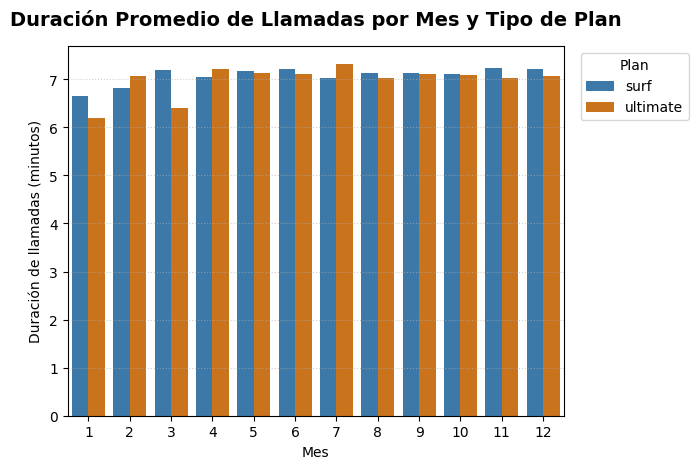

In [34]:
palette = {'surf': '#2b7bba', 'ultimate': '#e67300'}
ax = sns.barplot(data=df_duracion_prom,
            x='month',
            y='duracion_llamadas_prom_minutos',
            hue='plan_name',
            palette=palette)

ax.set_title('Duración Promedio de Llamadas por Mes y Tipo de Plan', fontsize=14, weight='bold', pad=15)
ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    title='Plan',
    frameon=True,
)
ax.set_xlabel('Mes')
ax.set_ylabel('Duración de llamadas (minutos)')
ax.grid(axis='y', linestyle=':', alpha=0.6);


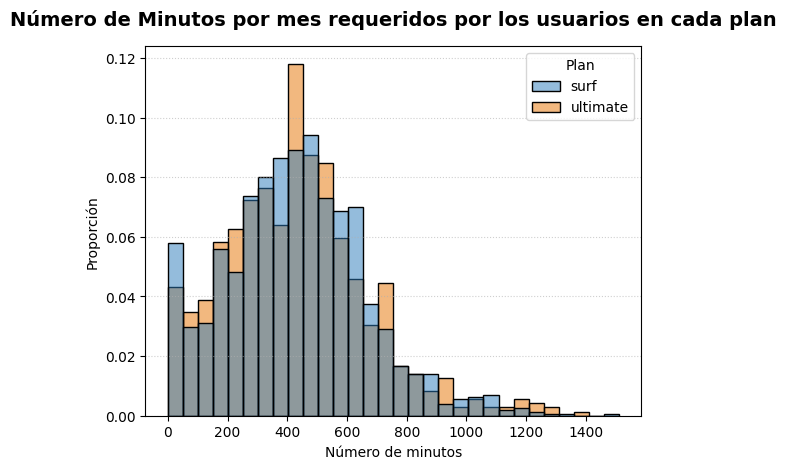

In [35]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.
ax_hist = sns.histplot(data=df_calls_month,
                  x="nro_minutos",
                  hue="plan_name",
                  bins=30,
                  stat='probability',
                  common_norm=False,
                  alpha=0.5,
                  hue_order=['surf','ultimate'],
                  palette=palette)

ax_hist.set_title('Número de Minutos por mes requeridos por los usuarios en cada plan', fontsize=14, weight='bold', pad=15)
ax_hist.set_ylabel("Proporción")
ax_hist.grid(axis='y', linestyle=':', alpha=0.6)
ax_hist.set_xlabel("Número de minutos")
ax_hist.get_legend().set_title('Plan')

In [36]:
# Calcula la media y la varianza de la duración mensual de llamadas.
df_calls["duration_round"] = np.ceil(df_calls["duration"]).astype('Int64')   # ← 'Int64' con mayúscula
df_calls_grouped = df_calls_month.groupby('plan_name').agg(
    media_duracion=('duracion_llamadas_prom_minutos', 'mean'),
    desv_std_duracion=('duracion_llamadas_prom_minutos', 'std'),
    varianza_duracion=('duracion_llamadas_prom_minutos', 'var'),
    media_minutos=('nro_minutos', 'mean'),
    desv_std_minutos=('nro_minutos', 'std'),
    varianza_minutos=('nro_minutos', 'var')).astype(float).round(2)

df_calls_grouped

,media_duracion,desv_std_duracion,varianza_duracion,media_minutos,desv_std_minutos,varianza_minutos
plan_name,,,,,,
surf,7.16,1.11,1.23,428.75,234.45,54968.28
ultimate,7.08,0.96,0.92,430.45,240.51,57844.46


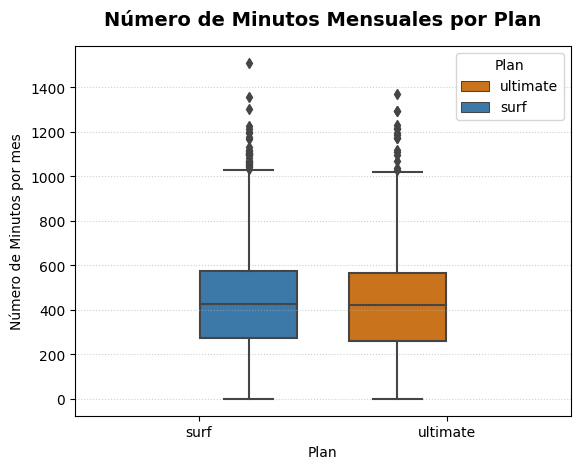

In [37]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas
ax_box=sns.boxplot(
    data=df_calls_month,
    x='plan_name',
    y='nro_minutos',
    hue='plan_name',
    order=['surf', 'ultimate'],
    palette=palette
)
ax_box.set_title('Número de Minutos Mensuales por Plan', fontsize=14, weight='bold', pad=15)
ax_box.set_ylabel("Número de Minutos por mes")
ax_box.grid(axis='y', linestyle=':', alpha=0.6)
ax_box.set_xlabel("Plan")
ax_box.get_legend().set_title('Plan')


**CONCLUSIONES:**   

- La duración promedio de las llamadas para los dos planes varían entre 6 y 7 minutos, lo que indica que los usuarios de ambos planes tienen un comportamiento similar en cuanto a la duración de las llamadas.
- La media de número de minutos mensuales para los dos planes es muy cercana, 428,75 para el plan Surf y 430,45 para el plan Ultimate, lo que indica que los usuarios de ambos planes tienen un comportamiento similar en cuanto al gasto mensual en llamadas.
- El 50% central de los registros está entre ≈270 y ≈570 minutos para ambos planes, lo que significa que consumen una cantidad de minutos similar y no hay una diferencia notable entre los dos planes en cuanto a la duración de las llamadas.
- Cerca del 6% de los registros del plan Surf y el ≈4% de los registros del plan Ultimate consumieron menos de 50 minutos en un mes determinado. Esto puede ser un comportamiento normal, pero es importante tenerlo en cuenta al analizar los datos y calcular los ingresos generados por cada usuario.
- Más de un 25% de los meses del plan Surf supera el límite de los 500 minutos incluidos en el paquete, debido a que el borde superior de la caja del IQR está cerca de los ≈570. Mientras que para el plan Ultimate en ninguno de los meses supera el límite de los 3000 minutos incluidos en el paquete; el valor máximo está cerca de los ≈1400 minutos. 
- El comportamiento general de los usuarios de ambos planes es muy similar, resultan hablando una cantidad de minutos similar y la diferencia entre los dos planes es mínima, por lo que no se puede determinar que un plan sea mejor que el otro en cuanto a la duración de las llamadas.

**NOTAS:**
Es importante resaltar que el histograma se realizó a partir del porcentaje de registros (usuarios-mes) en cada plan, pues existía una diferencia significativa en la cantidad de usuarios entre los dos planes, lo que podría haber sesgado la interpretación de los resultados si se hubiera realizado a partir del número de usuarios.

### Mensajes

In [38]:
# Compara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan
df_messages_month = df_cmi_monthly_plans_tar[['user_id', 'month', 'nro_mensajes', 'plan_name']]
df_messages_media = df_messages_month.groupby(by=['plan_name', 'month'], as_index=False)['nro_mensajes'].mean()
df_messages_media

,plan_name,month,nro_mensajes
0,surf,1,10.500000
1,surf,2,12.000000
2,surf,3,15.260870
3,surf,4,17.400000
4,surf,5,24.012987
5,surf,6,25.298969
6,surf,7,27.033058
7,surf,8,28.777778
8,surf,9,30.762887
9,surf,10,33.839662


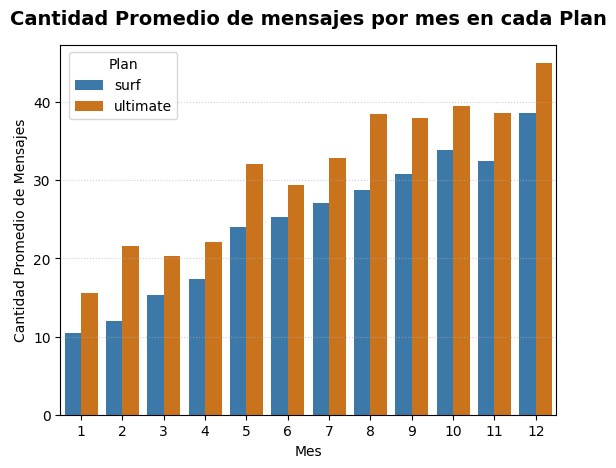

In [39]:
# Compara el número de mensajes por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
ax_messages = sns.barplot(data=df_messages_media,
            x='month',
            y='nro_mensajes',
            hue='plan_name',
            palette=palette)

ax_messages.set_title('Cantidad Promedio de mensajes por mes en cada Plan', fontsize=14, weight='bold', pad=15)
ax_messages.legend(
    loc='upper right',
    bbox_to_anchor=(0.25, 1),
    title='Plan',
    frameon=True,
)
ax_messages.set_xlabel('Mes')
ax_messages.set_ylabel('Cantidad Promedio de Mensajes')
ax_messages.grid(axis='y', linestyle=':', alpha=0.6);

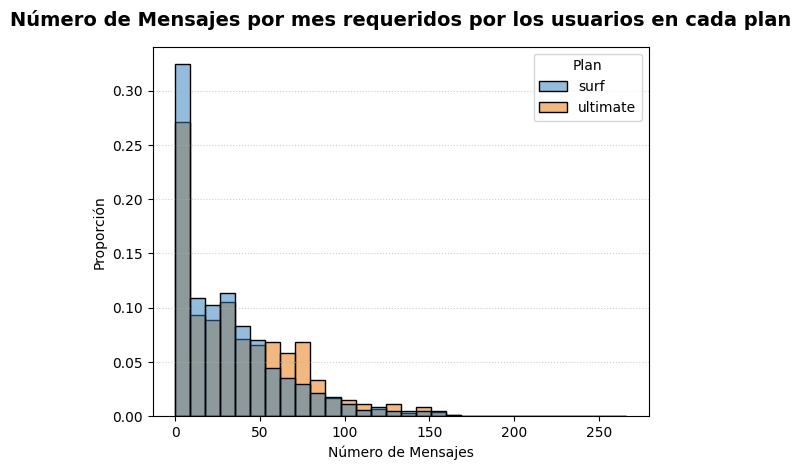

In [40]:
# Compara el número de mensajes mensuales que necesitan los usuarios de cada plan. Traza un histograma.
ax_hist_messages = sns.histplot(data=df_messages_month,
                  x="nro_mensajes",
                  hue="plan_name",
                  bins=30,
                  stat='probability',
                  common_norm=False,
                  alpha=0.5,
                  hue_order=['surf','ultimate'],
                  palette=palette)

ax_hist_messages.set_title('Número de Mensajes por mes requeridos por los usuarios en cada plan', fontsize=14, weight='bold', pad=15)
ax_hist_messages.set_ylabel("Proporción")
ax_hist_messages.grid(axis='y', linestyle=':', alpha=0.6)
ax_hist_messages.set_xlabel("Número de Mensajes")
ax_hist_messages.get_legend().set_title('Plan')

In [41]:
# Calcula la media y la varianza del número mensual de mensajes.
df_messages_grouped = df_messages_month.groupby('plan_name').agg(
    media_nro_mensajes=('nro_mensajes', 'mean'),
    desv_std_nro_mensajes=('nro_mensajes', 'std'),
    varianza_nro_mensajes=('nro_mensajes', 'var')).round(2)

df_messages_grouped

,media_nro_mensajes,desv_std_nro_mensajes,varianza_nro_mensajes
plan_name,,,
surf,31.16,33.57,1126.72
ultimate,37.55,34.77,1208.76


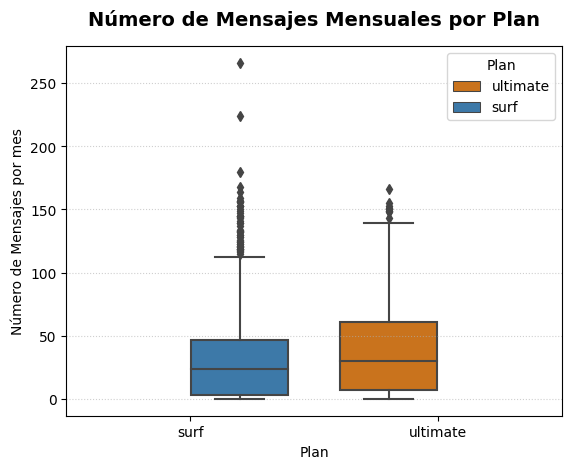

In [42]:
# Traza un diagrama de caja para visualizar la distribución del número de mensajes mensuales
ax_box_messages=sns.boxplot(
    data=df_messages_month,
    x='plan_name',
    y='nro_mensajes',
    hue='plan_name',
    order=['surf', 'ultimate'],
    palette=palette
)
ax_box_messages.set_title('Número de Mensajes Mensuales por Plan', fontsize=14, weight='bold', pad=15)
ax_box_messages.set_ylabel("Número de Mensajes por mes")
ax_box_messages.grid(axis='y', linestyle=':', alpha=0.6)
ax_box_messages.set_xlabel("Plan")
ax_box_messages.get_legend().set_title('Plan')


**CONCLUSIONES:**

- El promedio de mensajes enviados por los usuarios de ambos planes aumenta a medida que transcurre el tiempo, lo que indica que los usuarios de ambos planes tienden a enviar más mensajes a medida que pasa el tiempo.
- La media de mensajes enviados mensualmente por los usuarios del plan Surf es de ≈31 y el de los usuarios del plan Ultimate es de ≈37, lo que indica que los usuarios del plan Ultimate envían más mensajes que los usuarios del plan Surf. Lo cual, tiene lógica debido a que el 50% central del plan Surf está entre ≈3 y ≈47 mientras que el del plan Ultimate está entre ≈7 y ≈60. Teniendo una diferencia entre las medianas, pues la del plan ultimate (≈30) se encuentra por encima de la del plan surf (≈24).
- Los dos planes poseen una distribución sesgada a la derecha (asimetría positiva) y presentan valores atípicos. En mayor cantidad para el plan surf debido a que posee más usuarios que el plan ultimate.
- Cerca del 30% de los registros del plan Surf y el ≈25% de los registros del plan Ultimate enviaron menos de ≈10 mensajes en un mes determinado. Este es el mayor pico que se ve en la distribución para ambos planes.
- Para el plan Surf se tiene que hay un poco menos del ≈25% de los meses que superan el límite de los 50 mensajes incluidos en el paquete, mientras que para el plan ultimate no se acercan al límite, que son 1000 mensajes incluidos.
- Para este servicio de mensajería, existe una leve diferencia entre los dos planes, ya que el plan Ultimate tiene un promedio de mensajes enviados mayor que el plan Surf, lo que indica que los usuarios del plan Ultimate tienden a enviar más mensajes que los usuarios del plan Surf.

**NOTAS:**
Al igual que en el análisis de llamadas, es importante resaltar que el histograma se realizó a partir del porcentaje de registros (usuarios-mes) en cada plan, pues existía una diferencia significativa en la cantidad de usuarios entre los dos planes, lo que podría haber sesgado la interpretación de los resultados si se hubiera realizado a partir del número de usuarios.

### Internet

In [43]:
# Compara la cantidad de tráfico de Internet consumido por usuarios por plan
df_internet_month = df_cmi_monthly_plans_tar[['user_id', 'month', 'nro_sessions', 'total_mb_used', 'plan_name']].copy()
df_internet_month['total_gb_used'] = df_cmi_monthly_plans_tar['total_mb_used']/1024
df_internet_media = df_internet_month.groupby(by=['plan_name', 'month'], as_index=False)['total_gb_used'].mean()
df_internet_media

,plan_name,month,total_gb_used
0,surf,1,4.760605
1,surf,2,11.893402
2,surf,3,13.032656
3,surf,4,11.703323
4,surf,5,13.609722
5,surf,6,14.942900
6,surf,7,16.390235
7,surf,8,16.401691
8,surf,9,16.202570
9,surf,10,16.905601


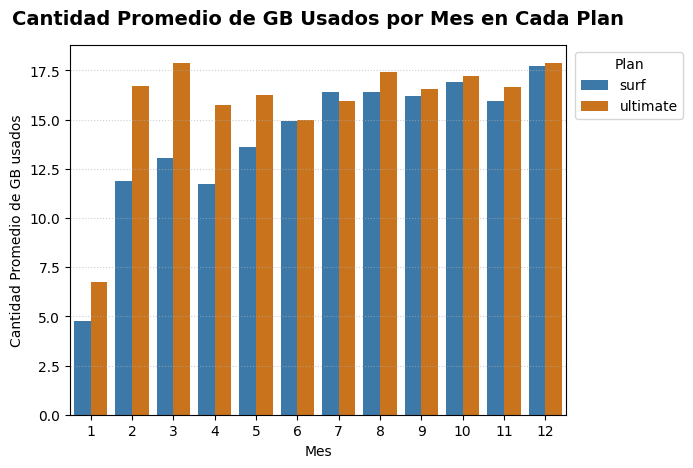

In [44]:
# Compara el total de gigabytes por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
ax_internet = sns.barplot(data=df_internet_media,
            x='month',
            y='total_gb_used',
            hue='plan_name',
            palette=palette)

ax_internet.set_title('Cantidad Promedio de GB Usados por Mes en Cada Plan', fontsize=14, weight='bold', pad=15)
ax_internet.legend(
    loc='upper right',
    bbox_to_anchor=(1.25, 1),
    title='Plan',
    frameon=True,
)
ax_internet.set_xlabel('Mes')
ax_internet.set_ylabel('Cantidad Promedio de GB usados')
ax_internet.grid(axis='y', linestyle=':', alpha=0.6);

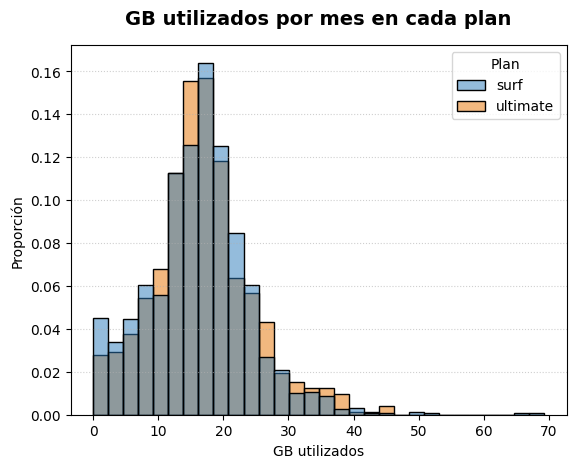

In [45]:
# Compara el total de Gigabytes mensuales que necesitan los usuarios de cada plan. Traza un histograma.
ax_hist_internet = sns.histplot(data=df_internet_month,
                  x="total_gb_used",
                  hue="plan_name",
                  bins=30,
                  stat='probability',
                  common_norm=False,
                  alpha=0.5,
                  hue_order=['surf','ultimate'],
                  palette=palette)

ax_hist_internet.set_title('GB utilizados por mes en cada plan', fontsize=14, weight='bold', pad=15)
ax_hist_internet.set_ylabel("Proporción")
ax_hist_internet.grid(axis='y', linestyle=':', alpha=0.6)
ax_hist_internet.set_xlabel("GB utilizados")
ax_hist_internet.get_legend().set_title('Plan')

In [46]:
# Calcula la media y la varianza del total de gigabytes usados mensualmente.
df_internet_grouped = df_internet_month.groupby('plan_name').agg(
    media_total_gb_used=('total_gb_used', 'mean'),
    desv_std_total_gb_used=('total_gb_used', 'std'),
    varianza_total_gb_used=('total_gb_used', 'var')).round(2)

df_internet_grouped

,media_total_gb_used,desv_std_total_gb_used,varianza_total_gb_used
plan_name,,,
surf,16.17,7.83,61.24
ultimate,16.81,7.67,58.80


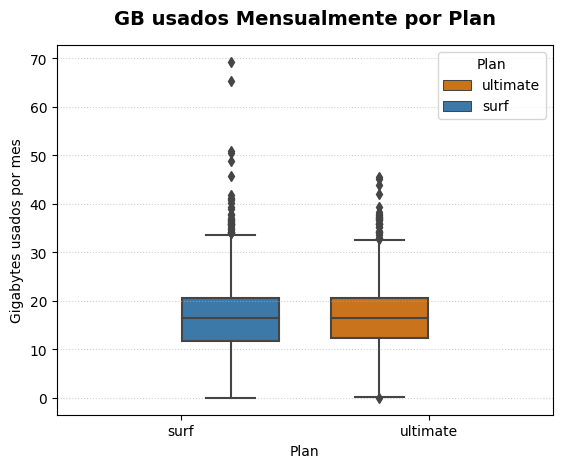

In [47]:
# Traza un diagrama de caja para visualizar la distribución del total de Gigabytes utilizados mensualmente
ax_box_internet=sns.boxplot(
    data=df_internet_month,
    x='plan_name',
    y='total_gb_used',
    hue='plan_name',
    order=['surf', 'ultimate'],
    palette=palette
)
ax_box_internet.set_title('GB usados Mensualmente por Plan', fontsize=14, weight='bold', pad=15)
ax_box_internet.set_ylabel("Gigabytes usados por mes")
ax_box_internet.grid(axis='y', linestyle=':', alpha=0.6)
ax_box_internet.set_xlabel("Plan")
ax_box_internet.get_legend().set_title('Plan')


**CONCLUSIONES:**

- En la mayoría de los meses, los usuarios del plan Surf y del plan ultimate consumen en promedio entre 11 y 17 GB de datos, lo que indica que los usuarios de ambos planes tienen un comportamiento similar en cuanto al consumo de datos.
- Los usuarios del plan de ultimate (16.81 GB) consumen en promedio más datos que los usuarios del plan surf (16.17 GB), sin embargo, la diferencia es mínima.
- Los datos poseen una distribución sesgada a la derecha (asimetría positiva) y presentan valores atípicos para ambos planes. Esta distribución presenta que el comportamiento de los usuarios es muy similar en cuanto al consumo de datos, y que la diferencia entre los dos planes es mínima.
- El 50% central de los registros se encuentra entre ≈12 y ≈20 GB para ambos planes, lo que significa que consumen una cantidad de datos similar y no hay una diferencia notable entre los dos planes en cuanto al consumo de datos.
- Se observa que la mayoría de los registros del plan surf superan los 15 GB incluidos en el paquete llegando hasta un máximo de ≈70GB, de por sí por la media (16.17) y la mediana (≈16.0) ya tienden a superar dicho límite. Por otro lado, para el plan ultimate se tiene una distribución parecida y también se supera el límite de los 30 GB incluidos pero en una proporción menor al del plan Surf y el máximo consumo está cerca de ≈45 GB.
- No existe una diferencia relevante entre los dos planes en cuanto al consumo de datos, ya que ambos planes tienen un comportamiento similar y la diferencia entre ellos es mínima.

**NOTAS:**
Al igual que en los análisis de llamadas y mensajes, es importante resaltar que el histograma se realizó a partir del porcentaje de registros (usuarios-mes) en cada plan, pues existía una diferencia significativa en la cantidad de usuarios entre los dos planes, lo que podría haber sesgado la interpretación de los resultados si se hubiera realizado a partir del número de usuarios.

## Ingreso

In [48]:
df_ingreso = df_cmi_monthly_plans_tar[['user_id', 'month', 'plan_name', 'ingreso_mensual']]
df_ingreso_media = df_ingreso.groupby(by=['plan_name', 'month'], as_index=False)['ingreso_mensual'].mean()
df_ingreso_media

,plan_name,month,ingreso_mensual
0,surf,1,20.0
1,surf,2,34.396667
2,surf,3,45.941304
3,surf,4,40.7106
4,surf,5,47.628182
5,surf,6,49.276289
6,surf,7,62.67405
7,surf,8,63.931173
8,surf,9,58.271495
9,surf,10,65.421224


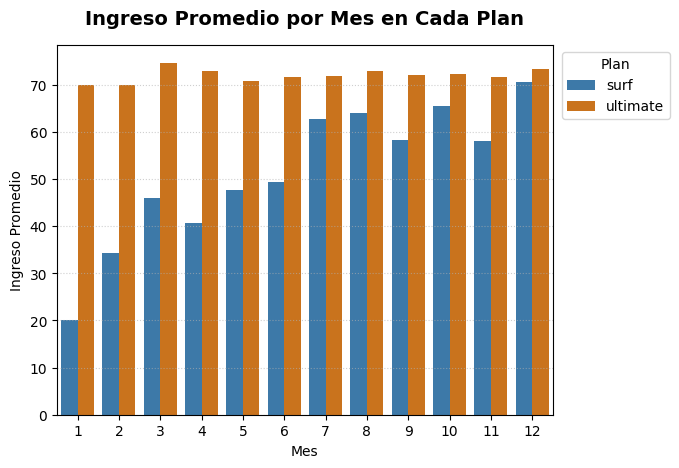

In [49]:
# Compara el ingreso por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
ax_ingreso = sns.barplot(data=df_ingreso_media,
            x='month',
            y='ingreso_mensual',
            hue='plan_name',
            palette=palette)

ax_ingreso.set_title('Ingreso Promedio por Mes en Cada Plan', fontsize=14, weight='bold', pad=15)
ax_ingreso.legend(
    loc='upper right',
    bbox_to_anchor=(1.25, 1),
    title='Plan',
    frameon=True,
)
ax_ingreso.set_xlabel('Mes')
ax_ingreso.set_ylabel('Ingreso Promedio')
ax_ingreso.grid(axis='y', linestyle=':', alpha=0.6);

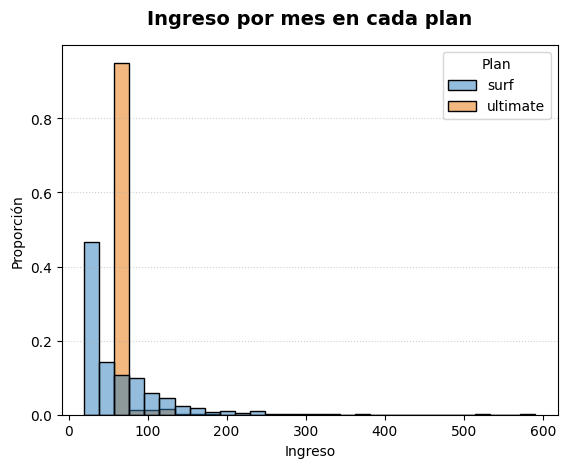

In [50]:
# Compara el ingreso mensual que necesitan los usuarios de cada plan. Traza un histograma.
ax_hist_ingreso = sns.histplot(data=df_ingreso,
                  x="ingreso_mensual",
                  hue="plan_name",
                  bins=30,
                  stat='probability',
                  common_norm=False,
                  alpha=0.5,
                  hue_order=['surf','ultimate'],
                  palette=palette)

ax_hist_ingreso.set_title('Ingreso por mes en cada plan', fontsize=14, weight='bold', pad=15)
ax_hist_ingreso.set_ylabel("Proporción")
ax_hist_ingreso.grid(axis='y', linestyle=':', alpha=0.6)
ax_hist_ingreso.set_xlabel("Ingreso")
ax_hist_ingreso.get_legend().set_title('Plan')

In [51]:
# Calcula la media y la varianza del ingreso mensual de cada plan.
df_ingreso_grouped = df_ingreso.groupby('plan_name').agg(
    media_ingreso=('ingreso_mensual', 'mean'),
    desv_std_ingreso=('ingreso_mensual', 'std'),
    varianza_ingreso=('ingreso_mensual', 'var'),
    ingreso_total=('ingreso_mensual', 'sum')).astype(float).round(2)

df_ingreso_grouped

,media_ingreso,desv_std_ingreso,varianza_ingreso,ingreso_total
plan_name,,,,
surf,60.71,55.39,3067.84,95491.18
ultimate,72.31,11.40,129.85,52066.00


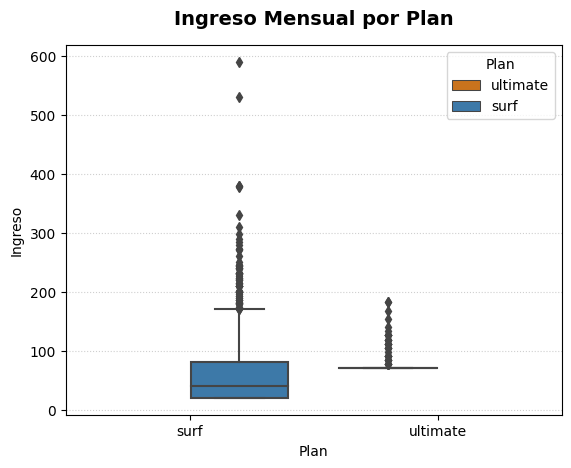

In [52]:
# Traza un diagrama de caja para visualizar la distribución del ingreso mensual
ax_box_ingreso=sns.boxplot(
    data=df_ingreso,
    x='plan_name',
    y='ingreso_mensual',
    hue='plan_name',
    order=['surf', 'ultimate'],
    palette=palette
)
ax_box_ingreso.set_title('Ingreso Mensual por Plan', fontsize=14, weight='bold', pad=15)
ax_box_ingreso.set_ylabel("Ingreso")
ax_box_ingreso.grid(axis='y', linestyle=':', alpha=0.6)
ax_box_ingreso.set_xlabel("Plan")
ax_box_ingreso.get_legend().set_title('Plan')

**Conclusiones:**

- El ingreso promedio mensual generado por los usuarios del plan Surf varía entre los 20 y 70 USD; adicionalmente, se observa una tendencia: a medida que pasa el tiempo, el usuario tiende a generar más ingresos. Mientras que el ingreso promedio mensual generado por los usuarios del plan Ultimate varía por encima de los 70 USD. Esto quiere decir que hay una variación de ingresos más amplia para el plan Surf, con una desviación estándar de 55.39 USD, mientras que para el plan Ultimate los ingresos son más consistentes, con una desviación estándar de 11.40 USD, y se mantienen por encima del pago mensual del plan.
- La media de ingresos generados por los usuarios del plan Surf es de 60.71 USD y por los usuarios del plan Ultimate es de 72.31 USD; sin embargo, el ingreso total generado por los usuarios del plan Surf (95,491 USD) es mayor que el que genera el plan Ultimate (52,066 USD).
- El 50% central de los registros del plan Surf se encuentra entre ≈20 y ≈80 USD, mientras que para el plan Ultimate no se observa una caja sino una línea cerca de ≈70 USD, y comparándolo con el histograma se ve que cerca del 95% de los registros pagan la cuota del plan, que es de 70 USD. Esto indica que los usuarios del plan Surf tienen un comportamiento más variado en cuanto a los ingresos generados, mientras que los usuarios del plan Ultimate tienen un comportamiento más consistente y estable.
- El plan Surf genera más ingresos en total porque tiene más usuarios que el plan Ultimate (339 usuarios vs. 161 usuarios), además de que los usuarios del plan Surf tienden a exceder los límites del paquete contratado en el servicio de datos, lo que genera ingresos adicionales para la compañía. Por otro lado, los usuarios del plan Ultimate tienden a mantenerse dentro de los límites del paquete contratado, lo que genera menos ingresos adicionales para la compañía.
- El comportamiento general de los registros del plan Surf tiene una mediana cercana a ≈40 USD y una media de 60.71 USD, lo que significa que los valores atípicos que se encuentran en el límite superior inflan la media. Por lo tanto, el cliente típico del plan Surf paga bastante menos que la media, mientras que el cliente típico del plan Ultimate paga cerca de la media.
- Algunos usuarios del plan Surf que pagan más de 70 USD al mes podrían pagar menos si cambiaran al plan Ultimate, cubriendo gran parte de los excedentes en los diferentes servicios.
- En general, si se analiza cuánto ingresa cada plan por usuario, se puede concluir que el plan Ultimate es el que genera más ingresos por usuario. Sin embargo, si se analiza cuánto ingresa cada plan en total, se puede concluir que el plan Surf es el que gana en este apartado.
- La significancia estadística de la diferencia de ingresos entre los dos planes se puede determinar mediante una prueba de hipótesis, la cual se realizará en la siguiente sección.

## Prueba las hipótesis estadísticas

#### 1. Prueba la hipótesis de que son diferentes los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf.

- **$H_0$**: "Los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf son iguales ($\mu_{surf}$ = $\mu_{ultimate}$)".

- **$H_1$**: "Los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf son diferentes ($\mu_{surf}$ ≠ $\mu_{ultimate}$)".

- **Nivel de significancia**: 0.05

De acuerdo con las hipótesis planteadas, se realizará una prueba t de Student que evaluará si las dos muestras independientes (ingresos de los usuarios del plan Surf y del plan Ultimate) provienen de poblaciones con medias iguales o diferentes.

Se usa `equal_var=False` porque las varianzas de los ingresos son muy diferentes: 3067,84 en Surf y 129,85 en Ultimate.

In [53]:
# Prueba las hipótesis
ingreso_surf = df_ingreso[df_ingreso['plan_name']=='surf']['ingreso_mensual'].astype(float)
ingreso_ultimate = df_ingreso[df_ingreso['plan_name']=='ultimate']['ingreso_mensual'].astype(float)
alpha = 0.05

st, p_value = stats.ttest_ind(ingreso_surf, ingreso_ultimate, equal_var=False, alternative="two-sided")
if p_value < alpha:
    print("Se rechaza H0, la diferencia entre los ingresos promedio es estadísticamente significativa")
else:
    print("No hay evidencia suficiente para rechazar H0")

print(f"\nEl valor P = {p_value}")

Se rechaza H0, la diferencia entre los ingresos promedio es estadísticamente significativa

El valor P = 3.1703905481135734e-15


De acuerdo con la anterior prueba de hipótesis, se obtiene un p-valor muy pequeño (3.17e-15), lo que indica que es menor a 0.05, por lo que se rechaza **$H_0$** a favor de **$H_1$**, lo que significa que los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf son diferentes. Ahora bien, cuando nos vamos a analizar los ingresos promedio de cada plan, se observa que el plan Ultimate tiene un ingreso promedio mayor (72.31 USD) que el plan Surf (60.71 USD), lo que confirma la diferencia en los ingresos entre ambos planes y que el plan Ultimate es el que genera más ingresos por usuario.

#### 2. Prueba la hipótesis de que el ingreso promedio de los usuarios del área NY-NJ es diferente al de los usuarios de otras regiones

- **$H_0$**: "Los ingresos promedio procedentes de los usuarios del área de NY-NJ son iguales a los de otras regiones ($\mu_{ny-nj}$ = $\mu_{otras}$)".

- **$H_1$**: "Los ingresos promedio procedentes de los usuarios del área de NY-NJ son diferentes a los de otras regiones ($\mu_{ny-nj}$ ≠ $\mu_{otras}$)".

- **Nivel de significancia**: 0.05

De acuerdo con las hipótesis planteadas, la prueba se realizará de la siguiente manera:

1. Se calculará la varianza de los ingresos de los usuarios del área NY-NJ y de los usuarios de otras regiones, para determinar si se puede asumir que las varianzas son iguales o diferentes.

2. Según los resultados del paso anterior, si las varianzas son muy distintas se usará la opción `equal_var=False`; si son similares, se usará `equal_var=True`.

3. Si la comparación de las varianzas no permite decidir con claridad, se aplicará la prueba de Levene: si su valor p es menor que 0,05, se usará `equal_var=False`; en caso contrario, `equal_var=True`.

4. Finalmente, se realizará una prueba t de Student para muestras independientes, que evaluará si los ingresos de los usuarios del área NY-NJ y los de otras regiones provienen de poblaciones con medias iguales o diferentes.

In [54]:
df_ingreso_cities = df_cmi_monthly_plans_tar[['user_id', 'month', 'city', 'ingreso_mensual']]
df_ingreso_NY_NJ = df_ingreso_cities[df_ingreso_cities['city']=='New York-Newark-Jersey City, NY-NJ-PA MSA']['ingreso_mensual'].astype(float)
df_ingreso_otros = df_ingreso_cities[df_ingreso_cities['city']!='New York-Newark-Jersey City, NY-NJ-PA MSA']['ingreso_mensual'].astype(float)

print(f"Varianza en ingresos NY-NJ = {df_ingreso_NY_NJ.var()}")
print(f"Varianza en ingresos otras ciudades = {df_ingreso_otros.var()}")
print(f"Equivalencia = {df_ingreso_otros.var()/df_ingreso_NY_NJ.var()}")
print(f"Media de ingresos NY-NJ = {df_ingreso_NY_NJ.mean()}")
print(f"Media de ingresos otras ciudades = {df_ingreso_otros.mean()}")

Varianza en ingresos NY-NJ = 1895.5456899204246
Varianza en ingresos otras ciudades = 2225.0479943518917
Equivalencia = 1.1738297874768187
Media de ingresos NY-NJ = 59.921352785145885
Media de ingresos otras ciudades = 65.2227713987474


Se observa que las varianzas de los ingresos de los usuarios del área NY-NJ y de los usuarios de otras regiones no difieren de forma notable, donde se observa que una es 1.17 veces la otra. Por lo tanto, se dice que son muy parecidas y se escoge la opción de `equal_var=True` para realizar la prueba t de Student.

In [55]:
# Prueba las hipótesis
alpha = 0.05

# Confirmación de la elección del equal_var
print("*----------------*")
print("Prueba Levene:")
stat, p = stats.levene(df_ingreso_NY_NJ, df_ingreso_otros)

if p < alpha:
    print("Las varianzas no son iguales, se rechaza la H0, equal_var = False")
else:
    print("Las varianzas son iguales, no se rechaza la H0, equal_var = True")
print(f"\nEl valor P de Levene = {p}")

print("*----------------*")
print("Prueba t Student:")
st, p_value = stats.ttest_ind(df_ingreso_NY_NJ, df_ingreso_otros, equal_var=True, alternative="two-sided")
if p_value < alpha:
    print("Se rechaza H0, la diferencia entre los ingresos promedio es estadísticamente significativa")
else:
    print("No hay evidencia suficiente para rechazar H0")

print(f"\nEl valor P = {p_value}")


*----------------*
Prueba Levene:
Las varianzas son iguales, no se rechaza la H0, equal_var = True

El valor P de Levene = 0.12580091109612837
*----------------*
Prueba t Student:
Se rechaza H0, la diferencia entre los ingresos promedio es estadísticamente significativa

El valor P = 0.043557431621342436


De acuerdo con los resultados, el valor P de la prueba t de Student es 0.043 y está cerca de 0.05, esto apunta a que la evidencia es débil. 

Sin embargo, al cumplirse que 0.044 es menor que 0.05, estos valores indican que se rechaza **$H_0$** a favor de **$H_1$**, lo que significa que los ingresos promedio procedentes de los usuarios del área de NY-NJ son diferentes a los de otras regiones. Ahora bien, cuando nos vamos a analizar los ingresos promedio de cada grupo, se observa que el área NY-NJ tiene un ingreso promedio menor (59.92 USD) que el resto de las regiones (65.22 USD), lo que confirma la diferencia en los ingresos entre ambos grupos y que las demás regiones son las que generan más ingresos por usuario.

## Conclusión general

1. **Por usuario, el plan Ultimate genera más ingresos y la diferencia es estadísticamente significativa.** El ingreso promedio mensual por usuario es de 72.31 USD en Ultimate y de 60.71 USD en Surf. La prueba t de Student (`equal_var=False`, por varianzas muy distintas: 3067.84 frente a 129.85) rechaza la igualdad de medias con un valor p ≈ 3.17e-15.

2. **En total, el plan Surf aporta casi el doble de ingresos, impulsado por el volumen de clientes y los excedentes de datos.** Surf genera 95,491 USD frente a 52,066 USD de Ultimate, porque tiene más del doble de usuarios (339 frente a 161). Además, más de la mitad de sus registros supera los 15 GB incluidos, a 10 USD por GB adicional. Por eso su ingreso es muy disperso (desviación estándar de 55.39 USD frente a 11.40 USD en Ultimate) y su mediana (≈40 USD) queda muy por debajo de la media (60.71 USD).

3. **Los usuarios de ambos planes se comportan de forma similar, pero los de Ultimate casi no aprovechan lo que pagan.** Los dos planes consumen en promedio unos 430 minutos y entre 16 y 17 GB al mes; Ultimate envía algo más de mensajes (37.55 frente a 31.16). Ningún usuario de Ultimate se acerca a los 3000 minutos ni a los 1000 mensajes incluidos, y solo unos pocos registros superan los 30 GB: cerca del 95% de sus registros paga únicamente la cuota de 70 USD.

4. **El área NY-NJ genera un ingreso promedio menor que el resto de las regiones, aunque con evidencia débil.** El ingreso promedio es de 59.92 USD en NY-NJ y de 65.22 USD en las demás regiones. Con varianzas similares (razón de 1.17, confirmada con la prueba de Levene, p ≈ 0.126) se aplicó la prueba t con `equal_var=True`: la diferencia es significativa al 5% (p ≈ 0.044), pero el valor p está cerca del umbral y no se sostendría con un nivel de significancia más exigente, como 0.01.

5. **Recomendaciones:**
    - **Priorizar el plan Ultimate en el presupuesto de publicidad para captar nuevos clientes.** Cada cliente nuevo de Ultimate genera en promedio 72.31 USD al mes, frente a 60.71 USD de Surf, y esta diferencia es estadísticamente significativa. Además, su ingreso es mucho más estable (con una desviación estándar de 11.40 USD frente a 55.39 USD), lo que hace más predecible el retorno de la inversión publicitaria. Surf genera más ingreso total por su mayor cantidad de clientes, pero esa ventaja proviene de la base actual de usuarios, no del valor de cada cliente nuevo que puede llegar en el futuro.
    - **Ofrecer el plan Ultimate a los usuarios de Surf que pagan más de 70 USD al mes, como estrategia de retención.** Estos usuarios superan con frecuencia los límites de datos y pagarían menos con Ultimate. El cambio reduciría el ingreso de cada uno de ellos, pero podría evitar que abandonen la compañía por facturas altas e impredecibles. Antes de aplicarla, conviene comparar el ingreso que se dejaría de percibir con el riesgo de perder a esos clientes.
    - **Evaluar y Diseñar un plan intermedio entre Surf y Ultimate.** Más de la mitad de los registros de Surf supera los 15 GB incluidos, mientras que los usuarios de Ultimate casi no aprovechan los 3000 minutos ni los 1000 mensajes que pagan. Un plan con más datos que Surf y un precio menor que Ultimate podría ajustarse mejor al consumo real de muchos usuarios y mejorar su satisfacción.
    - **Analizar el mercado de NY-NJ antes de ajustar la estrategia en esa región.** Es el área con más clientes de la muestra (80) y su ingreso promedio por usuario es menor que el grupo del resto de las regiones (59.92 USD frente a 65.22 USD). Sin embargo, la evidencia es débil (valor p ≈ 0.044), por lo que conviene revisar primero qué explica esa diferencia antes de modificar las campañas. Es decir, si estas diferencias se dan por la proporción de usuarios de cada plan en la región, por falta de cuota de mercado, desconocimiento de la existencia de los planes en las regiones, etc.